In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf
from statsmodels.tsa.stattools import adfuller, kpss
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score, mean_absolute_percentage_error

In [4]:
# Download data from yfinance
ticker = ["^GSPC", "^HSI", "0386.HK", "0388.HK", "0005.HK"]
df = [yf.download(i, start="2023-01-01", end="2026-09-30",auto_adjust=True, progress=False
                  ).droplevel(['Ticker'], axis=1).reset_index(drop=False).rename_axis(i)
                  for i in ticker]

In [5]:
# Create feature columns
data = []
for i in range(len(ticker)):
    cf = pd.DataFrame({})
    cf['Date'] = df[i].Date
    cf['Close'] = df[i].Close
    cf['Return'] = df[i].Close.pct_change()
    cf['Target'] = cf.Return.shift(-1)
    cf['MA5'] = df[i].Close.rolling(5).mean()
    cf['MA20'] = df[i].Close.rolling(20).mean()
    cf['BIAS5'] = df[i].Close / cf.MA5 -1
    cf['BIAS20'] = df[i].Close / cf.MA20 -1
    cf['MA5_to_MA20'] = cf.MA5 / cf.MA20 -1
    cf['CV_5'] = df[i].Close.rolling(5).std() / cf.MA5
    cf['CV_20'] = df[i].Close.rolling(5).std() / cf.MA20
    cf['Vol_std_5'] = df[i].Volume.rolling(5).std()
    cf['Vol_std_20'] = df[i].Volume.rolling(20).std()
    cf['Vol_scaled'] = cf.Vol_std_5 / cf.Vol_std_20 -1
    cf['Return_std_5'] = cf.Return.rolling(5).std()
    cf['Return_std_20'] = cf.Return.rolling(20).std()
    cf['Return_scaled'] = cf.Return_std_5 / cf.Return_std_20 -1
    cf.dropna(axis=0, inplace=True)
    data.append(cf.drop(columns=['Return','MA5','MA20','Vol_std_5','Vol_std_20','Return_std_5','Return_std_20']))

In [6]:
data[1].info()

<class 'pandas.DataFrame'>
RangeIndex: 897 entries, 20 to 916
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype        
---  ------         --------------  -----        
 0   Date           897 non-null    datetime64[s]
 1   Close          897 non-null    float64      
 2   Target         897 non-null    float64      
 3   BIAS5          897 non-null    float64      
 4   BIAS20         897 non-null    float64      
 5   MA5_to_MA20    897 non-null    float64      
 6   CV_5           897 non-null    float64      
 7   CV_20          897 non-null    float64      
 8   Vol_scaled     897 non-null    float64      
 9   Return_scaled  897 non-null    float64      
dtypes: datetime64[s](1), float64(9)
memory usage: 70.2 KB


# Functions

In [17]:
# Function for stationary checking
def checkstation(dataseries):
    adf_result = adfuller(dataseries, autolag="AIC", result_object=False)
    print("ADF Test Statistic:", adf_result[0])
    print("ADF P-Value:", adf_result[1])
    if adf_result[1] < 0.05:
        print("The series is stationary based on the ADF test (p-value < 0.05).")
    else:
        print("The series is non-stationary based on the ADF test (p-value >= 0.05).")

    kpss_result = kpss(dataseries, regression='c', result_object=False)
    print("\nKPSS Test Statistic:", kpss_result[0])
    print("KPSS P-Value:", kpss_result[1])
    if kpss_result[1] < 0.05:
        print("The series is non-stationary based on the KPSS test (p-value < 0.05).")
    else:
        print("The series is stationary based on the KPSS test (p-value >= 0.05).")

In [59]:
# Function for randomforest regression
def regression(df, target, features):
    y_reg = df[target]
    X_reg = df[features]

    split_idx = int(len(df)*0.8)
    X_train_r, X_test_r = X_reg.iloc[:split_idx], X_reg.iloc[split_idx:]
    y_train_r, y_test_r = y_reg.iloc[:split_idx], y_reg.iloc[split_idx:]

    tscv = TimeSeriesSplit(n_splits=5)
    
    param_grid = [
        {'n_estimators': [100, 200], 'max_depth': [3, 4, 5], 'min_samples_leaf': [20, 30]}
    ]
    grid_search = GridSearchCV(RandomForestRegressor(random_state=42), 
                               param_grid, n_jobs=-1, cv=tscv,
                               scoring='neg_mean_squared_error',
                               return_train_score=True)
    grid_search.fit(X_train_r, y_train_r)
    
    reg_model = grid_search.best_estimator_
    y_pred_r = reg_model.predict(X_test_r)
    importances = reg_model.feature_importances_

    print("Regression Done")
    print("Parameter Weights:")
    for name, weight in zip(features, importances):
        print(f"{name:<10} : {weight * 100:.2f}%")
    print("\nAccurcy Measure:")
    print(f"MAE      : {mean_absolute_error(y_test_r, y_pred_r):.4f}")
    print(f"RMSE     : {root_mean_squared_error(y_test_r, y_pred_r):.4f}")
    print(f"MAPE     : {mean_absolute_percentage_error(y_test_r, y_pred_r):.4}")
    print(f"R2 Score : {r2_score(y_test_r, y_pred_r):.4f}")
    
    return y_test_r, y_pred_r

In [19]:
# Function for result visualization
def plotresult_regression(df, y_test_r, y_pred_r):
    plt.plot(df.Date[-len(y_test_r):], y_test_r, 'c-', label='Actual Data', linewidth=1)
    plt.plot(df.Date[-len(y_test_r):], y_pred_r, 'r--', label="Predicted Data", linewidth=2, alpha=0.8)

    plt.grid(alpha=0.6)
    plt.legend(fontsize=11)
    plt.xticks(rotation=45, ha='right')

    plt.tight_layout()
    plt.show()

In [20]:
# Function for converting the predicted result from predicted return to predicted closing price
def result_close(df, y_test_r, y_pred_r):
    pred_date_range = df.Date[-len(y_test_r):]
    pred_data = pd.DataFrame(pred_date_range) 
    pred_data['Pre_Return'] = y_pred_r
    pred_data['Close'] = df.Close.copy()
    pred_data['Cumulative_Return'] = (1 + pred_data.Pre_Return).cumprod().shift(1).fillna(1)
    pred_data['Pre_Close'] = pred_data.Close.iloc[0]*pred_data.Cumulative_Return
    
    print(f"MAE      : {mean_absolute_error(pred_data.Close, pred_data.Pre_Close):.4f}")
    print(f"RMSE     : {root_mean_squared_error(pred_data.Close, pred_data.Pre_Close):.4f}")
    print(f"MAPE     : {mean_absolute_percentage_error(pred_data.Close, pred_data.Pre_Close):.4}")
    print(f"R2 Score : {r2_score(pred_data.Close, pred_data.Pre_Close):.4f}")
    return pred_data.Close, pred_data.Pre_Close

# Data Analyst

## Check stationary

In [21]:
for i in range(len(ticker)):
    print(f"\n{data[i].index.name}")
    print("Close")
    checkstation(df[i].Close)
    print("\nReturn")
    checkstation(df[i].Close.pct_change().dropna())


^GSPC
Close
ADF Test Statistic: -0.4184385574400953
ADF P-Value: 0.906974381043276
The series is non-stationary based on the ADF test (p-value >= 0.05).

KPSS Test Statistic: 4.609783124950795
KPSS P-Value: 0.01
The series is non-stationary based on the KPSS test (p-value < 0.05).

Return
ADF Test Statistic: -17.119010396036447
ADF P-Value: 7.278189330455258e-30
The series is stationary based on the ADF test (p-value < 0.05).

KPSS Test Statistic: 0.03770255787606161
KPSS P-Value: 0.1
The series is stationary based on the KPSS test (p-value >= 0.05).

^HSI
Close
ADF Test Statistic: -1.2068477631359158
ADF P-Value: 0.6706430618165052
The series is non-stationary based on the ADF test (p-value >= 0.05).

KPSS Test Statistic: 3.7182478189425097
KPSS P-Value: 0.01
The series is non-stationary based on the KPSS test (p-value < 0.05).

Return


C:\Users\ryanp\AppData\Local\Temp\ipykernel_15716\3464954749.py:11: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_result = kpss(dataseries, regression='c', result_object=False)
C:\Users\ryanp\AppData\Local\Temp\ipykernel_15716\3464954749.py:11: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_result = kpss(dataseries, regression='c', result_object=False)
C:\Users\ryanp\AppData\Local\Temp\ipykernel_15716\3464954749.py:11: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_result = kpss(dataseries, regression='c', result_object=False)
C:\Users\ryanp\AppData\Local\Temp\ipykernel_15716\3464954749.py:11: InterpolationWarning

ADF Test Statistic: -30.670844234499484
ADF P-Value: 0.0
The series is stationary based on the ADF test (p-value < 0.05).

KPSS Test Statistic: 0.1013605358895501
KPSS P-Value: 0.1
The series is stationary based on the KPSS test (p-value >= 0.05).

0386.HK
Close
ADF Test Statistic: -2.71551611791082
ADF P-Value: 0.07139157282888267
The series is non-stationary based on the ADF test (p-value >= 0.05).

KPSS Test Statistic: 2.5206150826196163
KPSS P-Value: 0.01
The series is non-stationary based on the KPSS test (p-value < 0.05).

Return
ADF Test Statistic: -30.73423695680341
ADF P-Value: 0.0
The series is stationary based on the ADF test (p-value < 0.05).

KPSS Test Statistic: 0.062304337847519216
KPSS P-Value: 0.1
The series is stationary based on the KPSS test (p-value >= 0.05).

0388.HK
Close
ADF Test Statistic: -1.0845561573842397
ADF P-Value: 0.7211912729288819
The series is non-stationary based on the ADF test (p-value >= 0.05).

KPSS Test Statistic: 3.487357522454003
KPSS P-Value

C:\Users\ryanp\AppData\Local\Temp\ipykernel_15716\3464954749.py:11: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_result = kpss(dataseries, regression='c', result_object=False)
C:\Users\ryanp\AppData\Local\Temp\ipykernel_15716\3464954749.py:11: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_result = kpss(dataseries, regression='c', result_object=False)
C:\Users\ryanp\AppData\Local\Temp\ipykernel_15716\3464954749.py:11: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_result = kpss(dataseries, regression='c', result_object=False)


ADF Test Statistic: -15.297097073097017
ADF P-Value: 4.36329168657757e-28
The series is stationary based on the ADF test (p-value < 0.05).

KPSS Test Statistic: 0.10666578237387644
KPSS P-Value: 0.1
The series is stationary based on the KPSS test (p-value >= 0.05).

0005.HK
Close
ADF Test Statistic: 1.0129365843158622
ADF P-Value: 0.9944005864430585
The series is non-stationary based on the ADF test (p-value >= 0.05).

KPSS Test Statistic: 4.438968925495685
KPSS P-Value: 0.01
The series is non-stationary based on the KPSS test (p-value < 0.05).

Return
ADF Test Statistic: -18.6880102347338
ADF P-Value: 2.040092859114773e-30
The series is stationary based on the ADF test (p-value < 0.05).

KPSS Test Statistic: 0.060414840603441516
KPSS P-Value: 0.1
The series is stationary based on the KPSS test (p-value >= 0.05).


C:\Users\ryanp\AppData\Local\Temp\ipykernel_15716\3464954749.py:11: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_result = kpss(dataseries, regression='c', result_object=False)
C:\Users\ryanp\AppData\Local\Temp\ipykernel_15716\3464954749.py:11: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_result = kpss(dataseries, regression='c', result_object=False)
C:\Users\ryanp\AppData\Local\Temp\ipykernel_15716\3464954749.py:11: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_result = kpss(dataseries, regression='c', result_object=False)


## Check Correlation

Correlations between Close and Features


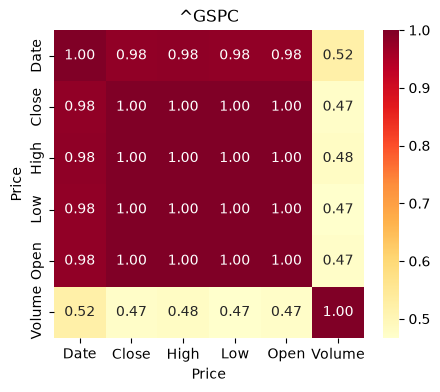

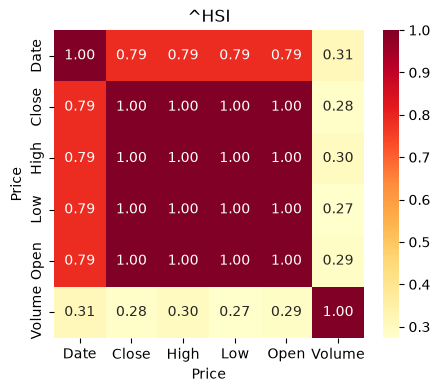

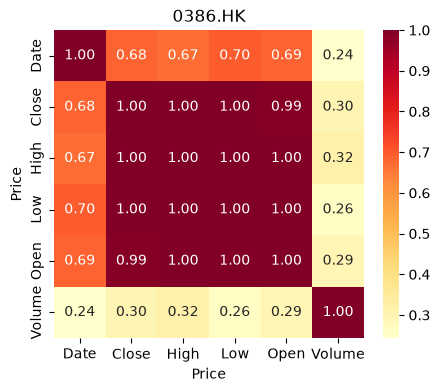

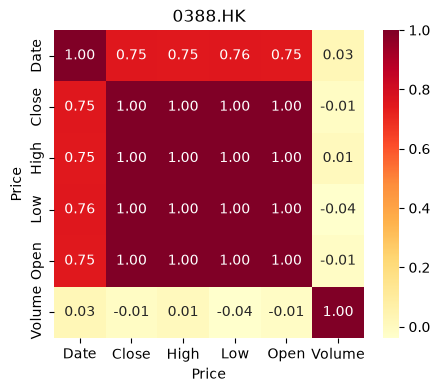

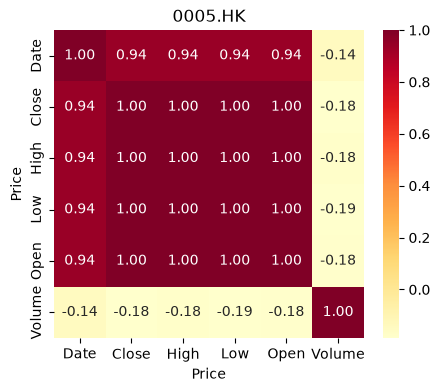

In [22]:
print("Correlations between Close and Features")
for i in range(len(ticker)):
    plt.figure(figsize=(5,4))
    sns.heatmap(df[i].corr(), annot=True, fmt='.2f', cmap='YlOrRd')
    plt.title(df[i].index.name)
    plt.show()

Correlation between Target Return and Features


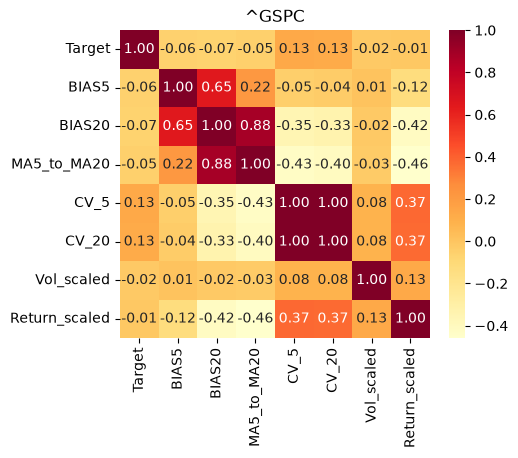

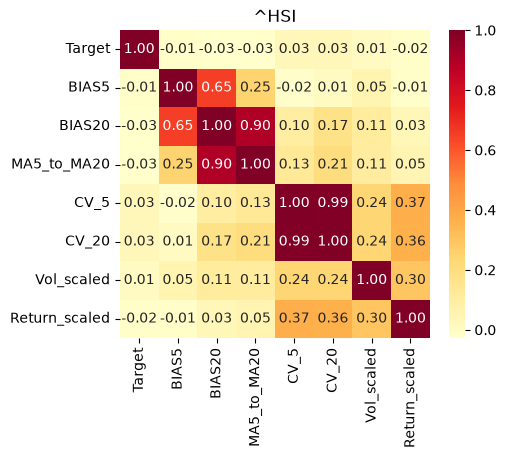

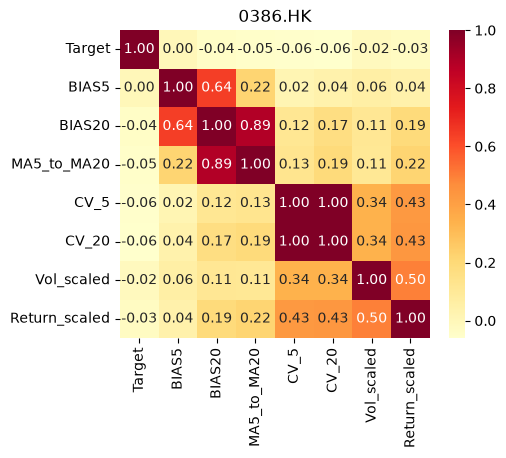

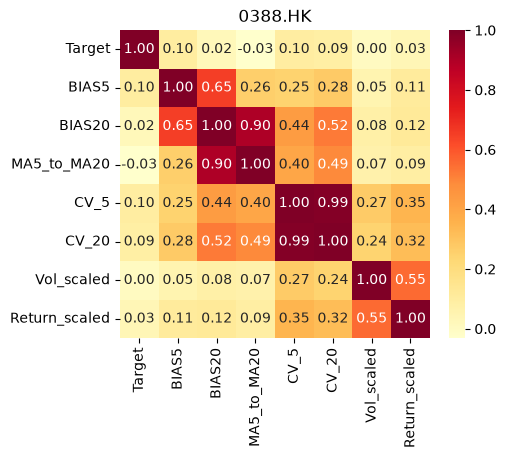

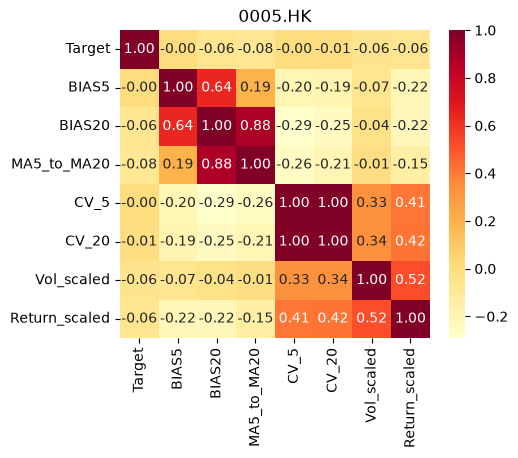

In [23]:
print("Correlation between Target Return and Features")
for i in range(len(ticker)):
    plt.figure(figsize=(5,4))
    sns.heatmap(data[i].drop(columns=['Date','Close']).corr(), 
                annot=True, fmt='.2f', cmap='YlOrRd')
    plt.title(data[i].index.name)
    plt.show()

## Hist

^GSPC


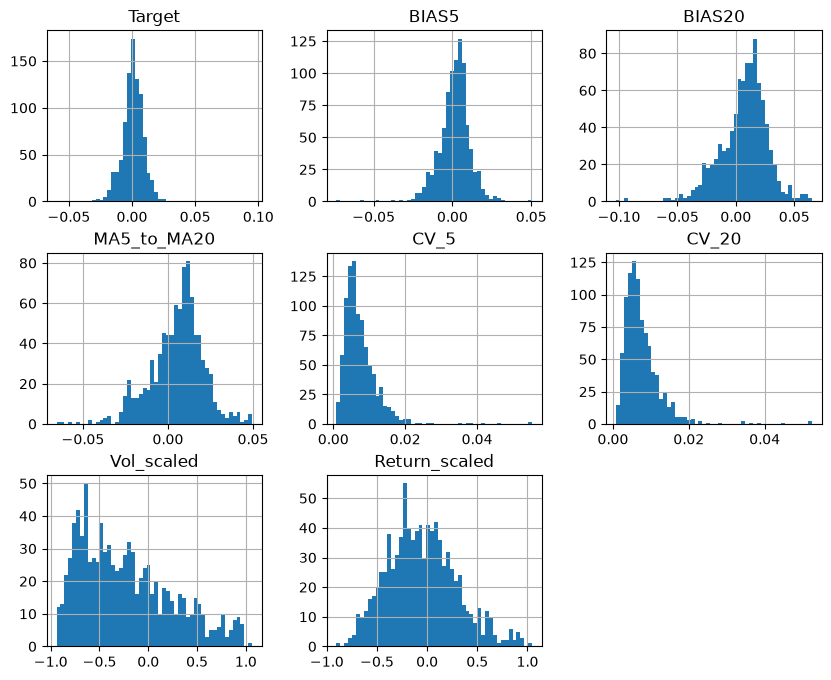

^HSI


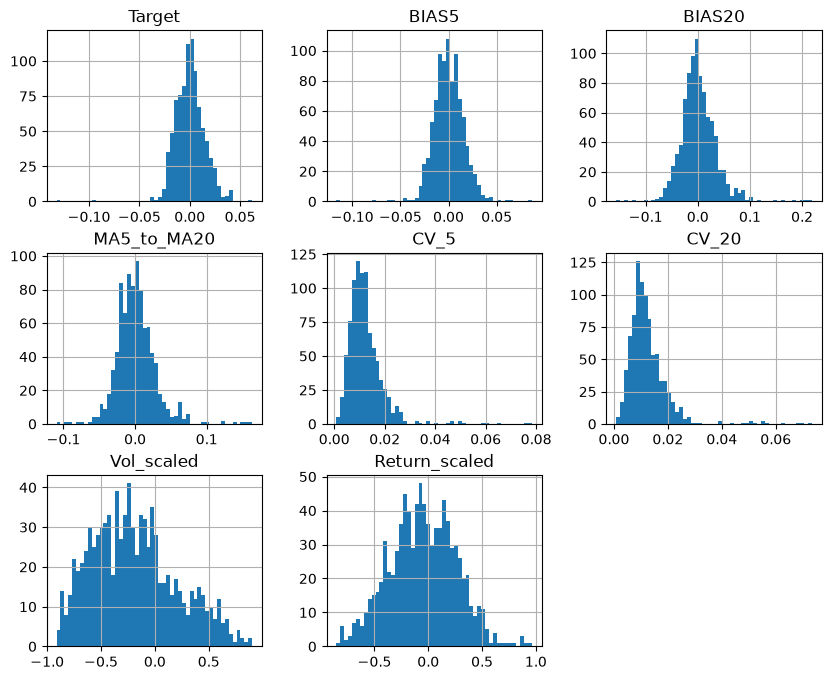

0386.HK


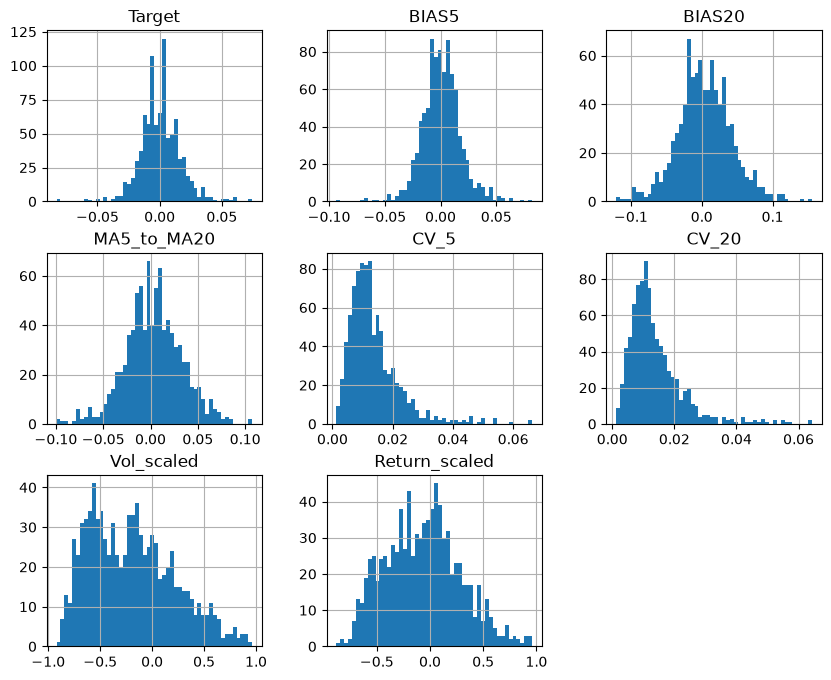

0388.HK


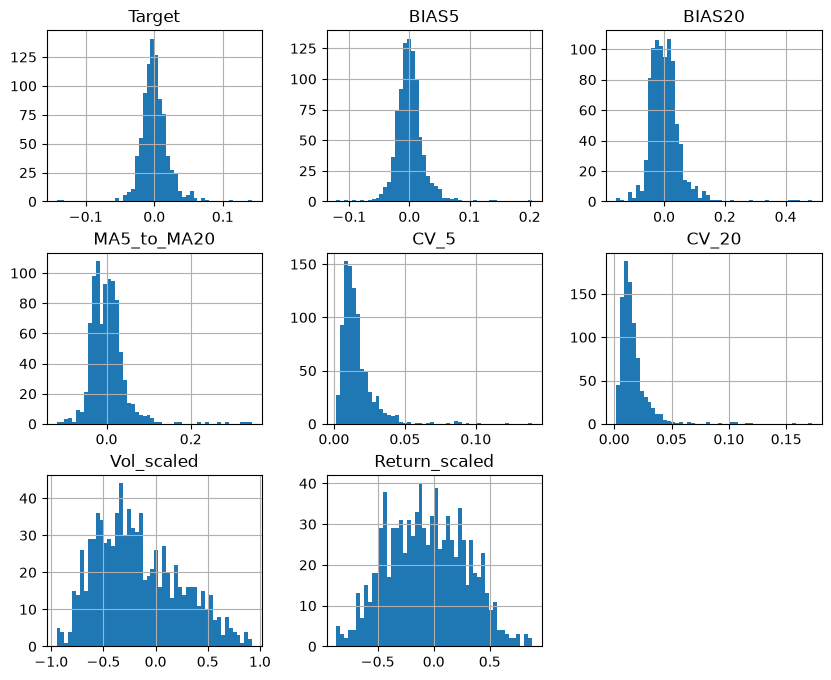

0005.HK


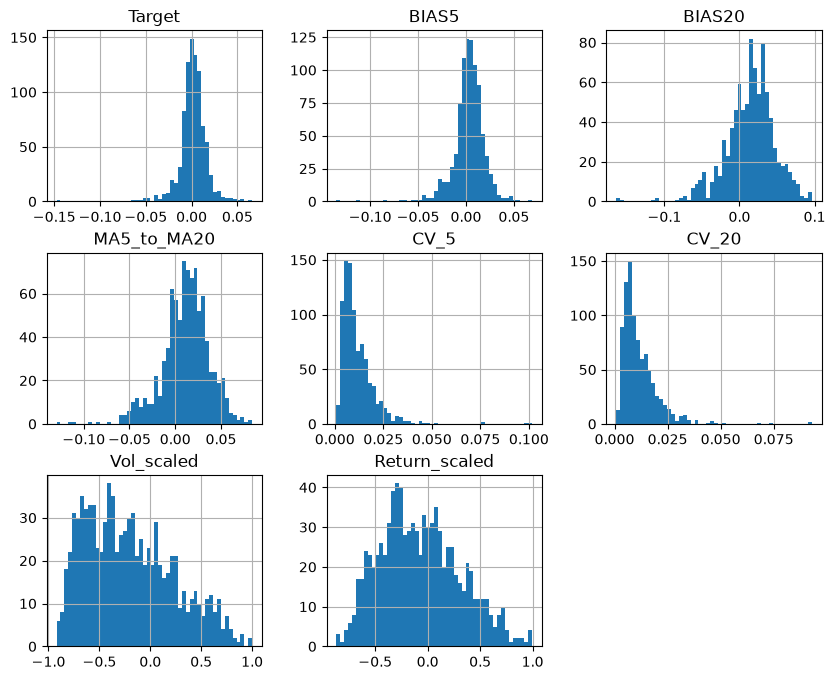

In [24]:
for i in range(len(ticker)):
    print(data[i].index.name)
    data[i].drop(columns=['Date','Close']).hist(bins=50, figsize=(10,8))
    plt.show()

## Stock Daily Close Plot

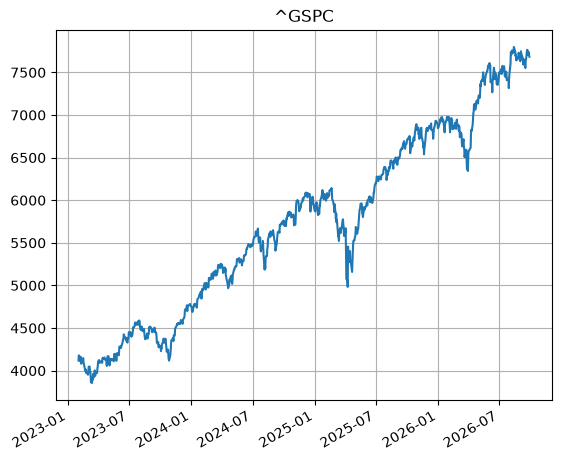

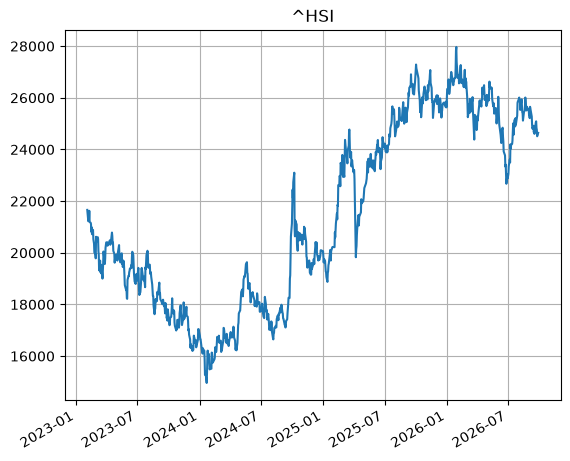

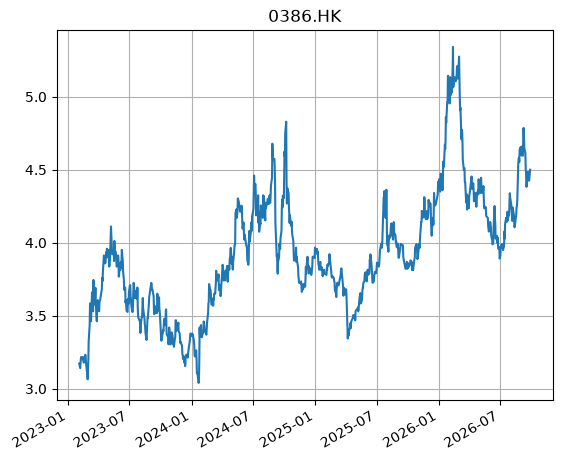

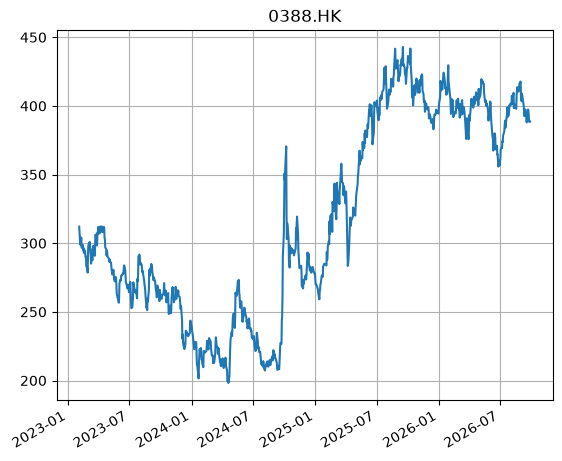

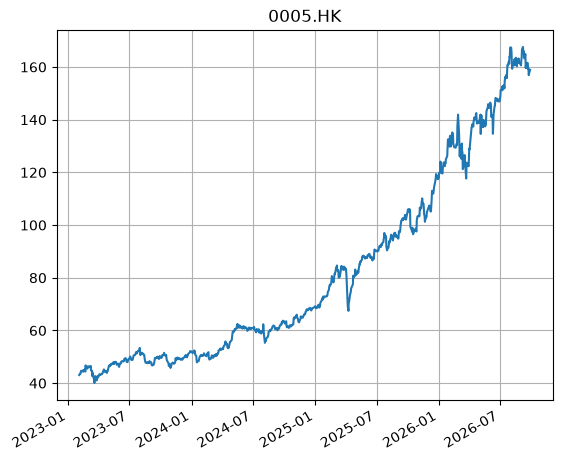

In [25]:
for i in range(len(ticker)):
    plt.figure()
    plt.plot(data[i].Date, data[i].Close)
    plt.title(f"{df[i].index.name}")
    plt.grid()
    plt.xticks(rotation=30, ha='right')
    plt.show()

# Stocks Regression


^GSPC
Regression Done
Parameter Weights:
BIAS5      : 13.93%
BIAS20     : 12.53%
MA5_to_MA20 : 31.90%
CV_5       : 4.95%
CV_20      : 12.08%
Vol_scaled : 13.75%
Return_scaled : 10.86%

Accurcy Measure:
MAE      : 0.0064
RMSE     : 0.0084
MAPE     : 3.995
R2 Score : -0.0086


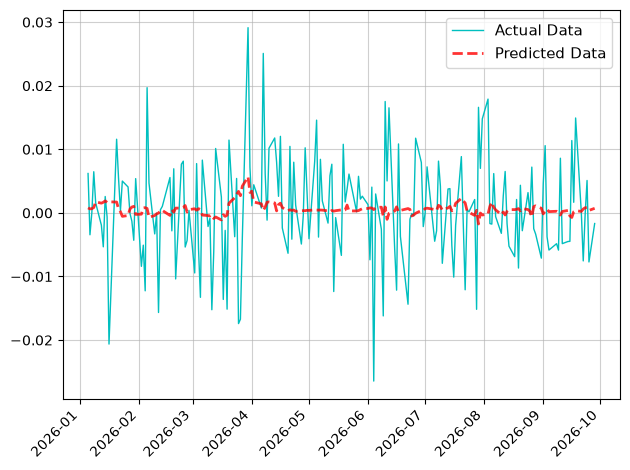

Close Measure:
MAE      : 155.0567
RMSE     : 227.4984
MAPE     : 0.02236
R2 Score : 0.6389


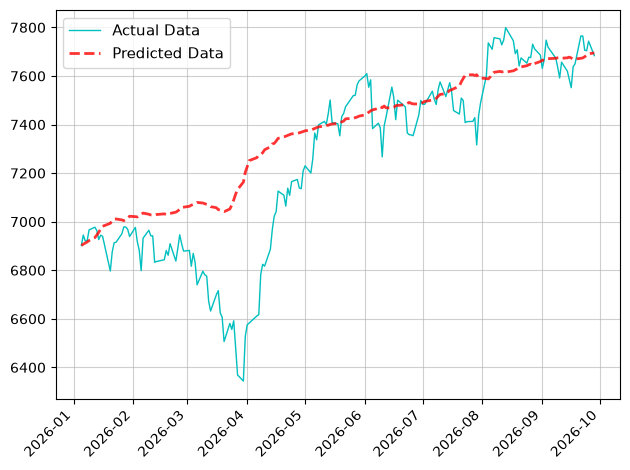


^HSI
Regression Done
Parameter Weights:
BIAS5      : 6.63%
BIAS20     : 22.36%
MA5_to_MA20 : 18.61%
CV_5       : 15.18%
CV_20      : 8.57%
Vol_scaled : 14.38%
Return_scaled : 14.27%

Accurcy Measure:
MAE      : 0.0095
RMSE     : 0.0117
MAPE     : 1.733
R2 Score : 0.0081


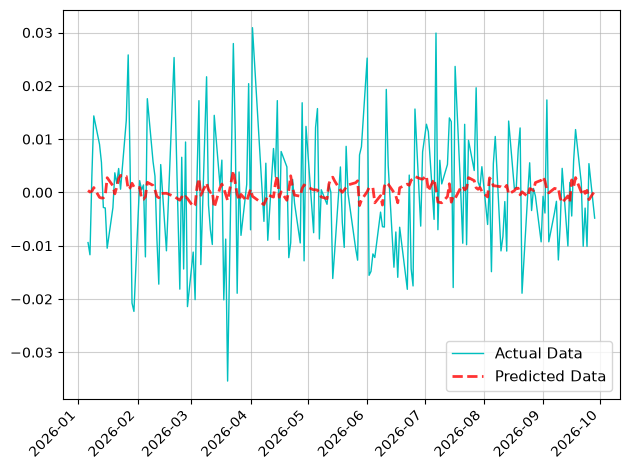

Close Measure:
MAE      : 1993.7815
RMSE     : 2404.4748
MAPE     : 0.07999
R2 Score : -5.0270


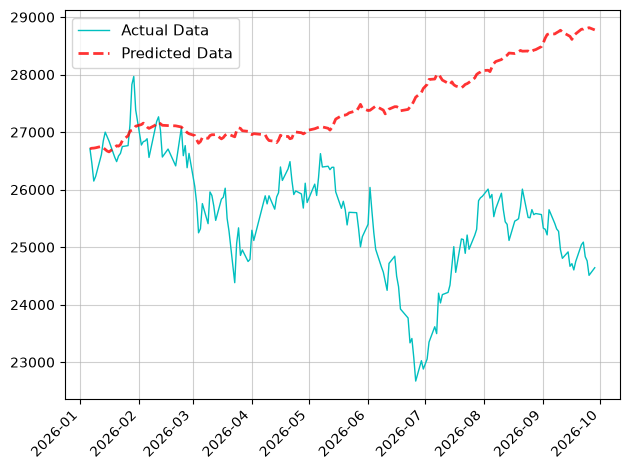


0386.HK
Regression Done
Parameter Weights:
BIAS5      : 11.61%
BIAS20     : 15.30%
MA5_to_MA20 : 33.02%
CV_5       : 8.23%
CV_20      : 10.48%
Vol_scaled : 10.15%
Return_scaled : 11.21%

Accurcy Measure:
MAE      : 0.0126
RMSE     : 0.0163
MAPE     : 6.608e+11
R2 Score : -0.0273


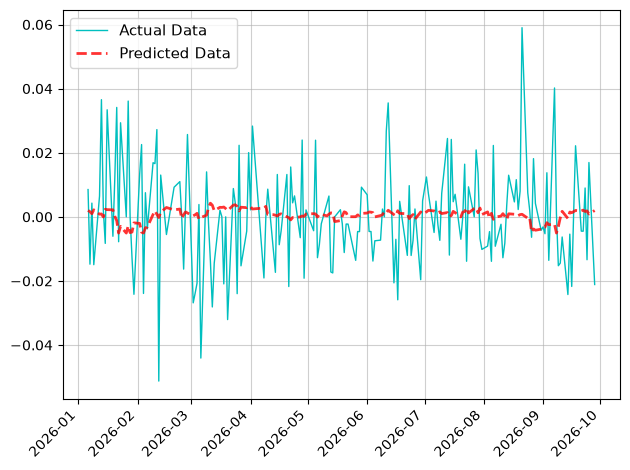

Close Measure:
MAE      : 0.4924
RMSE     : 0.5565
MAPE     : 0.1124
R2 Score : -1.5695


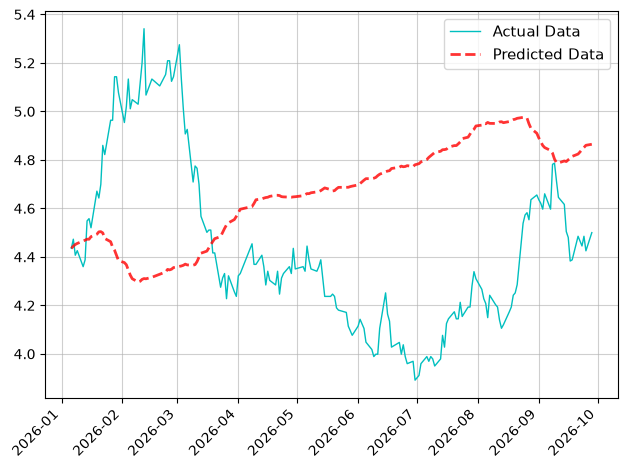


0388.HK
Regression Done
Parameter Weights:
BIAS5      : 13.87%
BIAS20     : 10.29%
MA5_to_MA20 : 25.99%
CV_5       : 14.10%
CV_20      : 10.98%
Vol_scaled : 12.00%
Return_scaled : 12.77%

Accurcy Measure:
MAE      : 0.0101
RMSE     : 0.0128
MAPE     : 6.304e+10
R2 Score : -0.0080


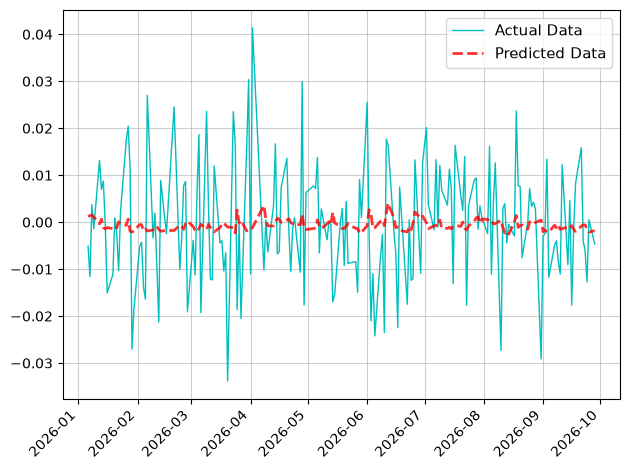

Close Measure:
MAE      : 12.2786
RMSE     : 14.8926
MAPE     : 0.0312
R2 Score : -0.0481


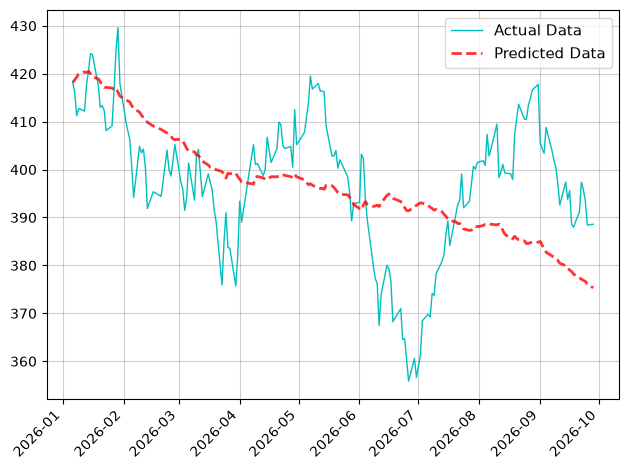


0005.HK
Regression Done
Parameter Weights:
BIAS5      : 28.86%
BIAS20     : 15.05%
MA5_to_MA20 : 14.78%
CV_5       : 7.99%
CV_20      : 6.74%
Vol_scaled : 14.53%
Return_scaled : 12.06%

Accurcy Measure:
MAE      : 0.0133
RMSE     : 0.0183
MAPE     : 2.761e+11
R2 Score : -0.0619


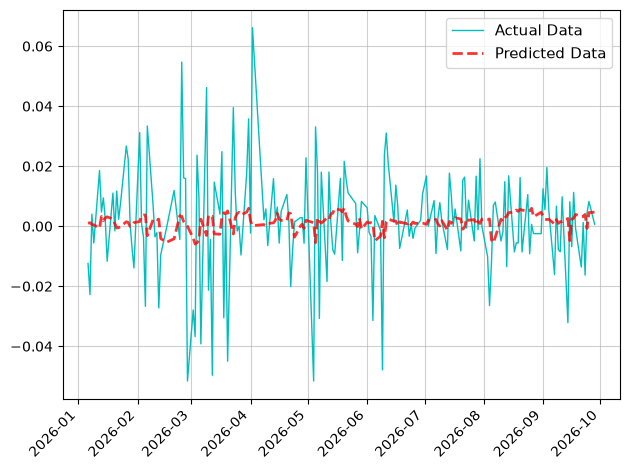

Close Measure:
MAE      : 6.4562
RMSE     : 7.9410
MAPE     : 0.04352
R2 Score : 0.6874


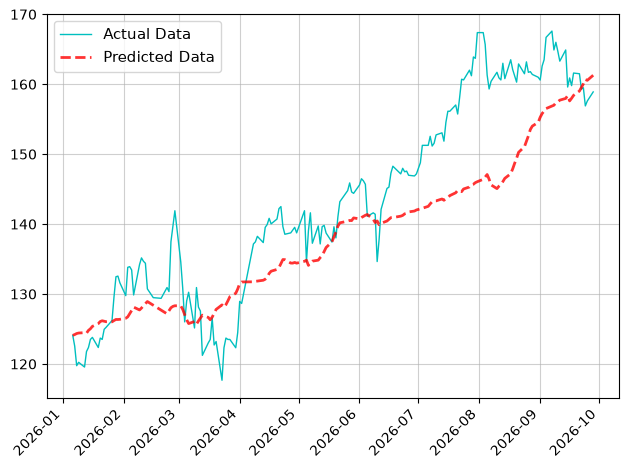

In [60]:
result = []
close_list = []

for i in range(len(ticker)):
    print(f"\n{data[i].index.name}")
    result.append(regression(data[i], 'Target', ['BIAS5', 'BIAS20', 'MA5_to_MA20', 'CV_5', 'CV_20', 'Vol_scaled', 'Return_scaled']))
    plotresult_regression(data[i], result[i][0], result[i][1])
    print("Close Measure:")
    close_list.append(result_close(data[i], result[i][0], result[i][1]))
    plotresult_regression(data[i], close_list[i][0], close_list[i][1])

## Output Result as CSV

In [61]:
result_ser_set = [pd.Series([format(mean_absolute_error(close_list[i][0], close_list[i][1]), ".4f"), 
                             format(root_mean_squared_error(close_list[i][0], close_list[i][1]), ".4f"), 
                             format(mean_absolute_percentage_error(close_list[i][0], close_list[i][1]), ".4%"), 
                             format(r2_score(close_list[i][0], close_list[i][1]), ".4f")],
                            index = ["MAE","RMSE","MAPE","R2 Score"],
                            name = ticker[i]) 
                  for i in range(len(ticker))]
result_df = pd.concat(result_ser_set, axis=1)
print("Closing price prediction accuracy:")
print(result_df)

Closing price prediction accuracy:
             ^GSPC       ^HSI   0386.HK  0388.HK  0005.HK
MAE       155.0567  1993.7815    0.4924  12.2786   6.4562
RMSE      227.4984  2404.4748    0.5565  14.8926   7.9410
MAPE       2.2356%    7.9990%  11.2372%  3.1204%  4.3524%
R2 Score    0.6389    -5.0270   -1.5695  -0.0481   0.6874


In [30]:
result_df.to_csv("randomforestresult.csv")

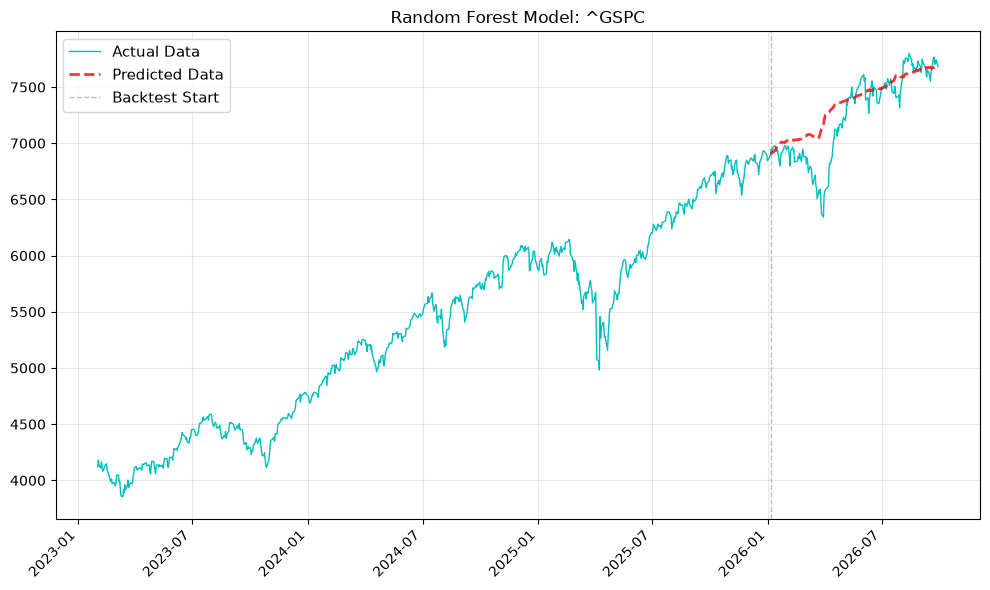

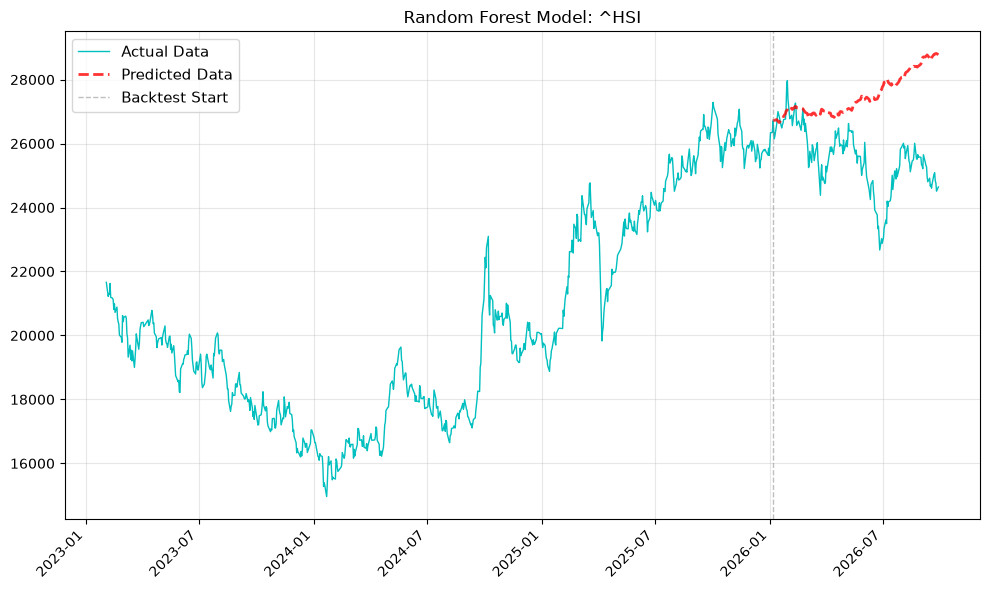

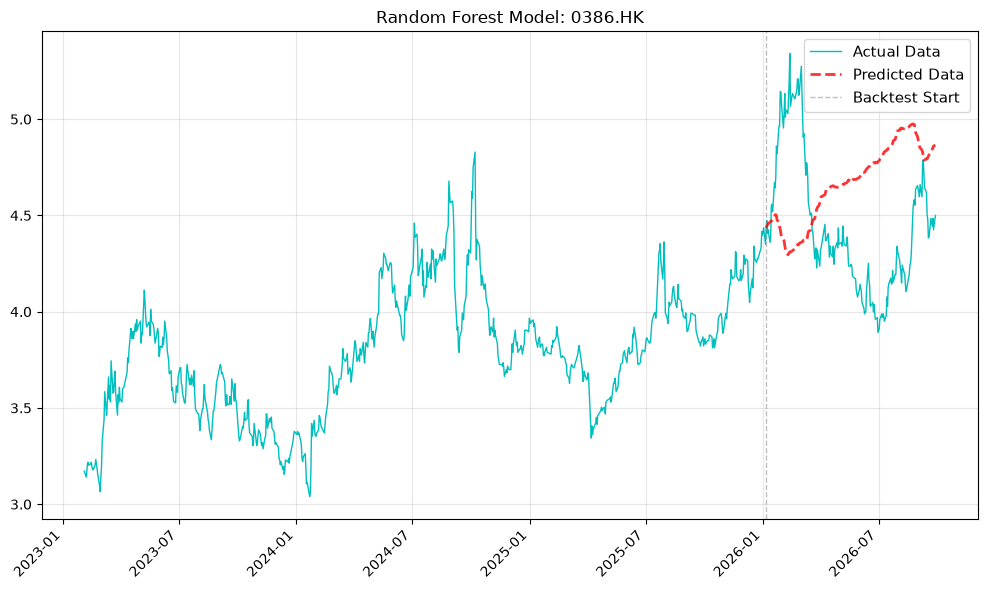

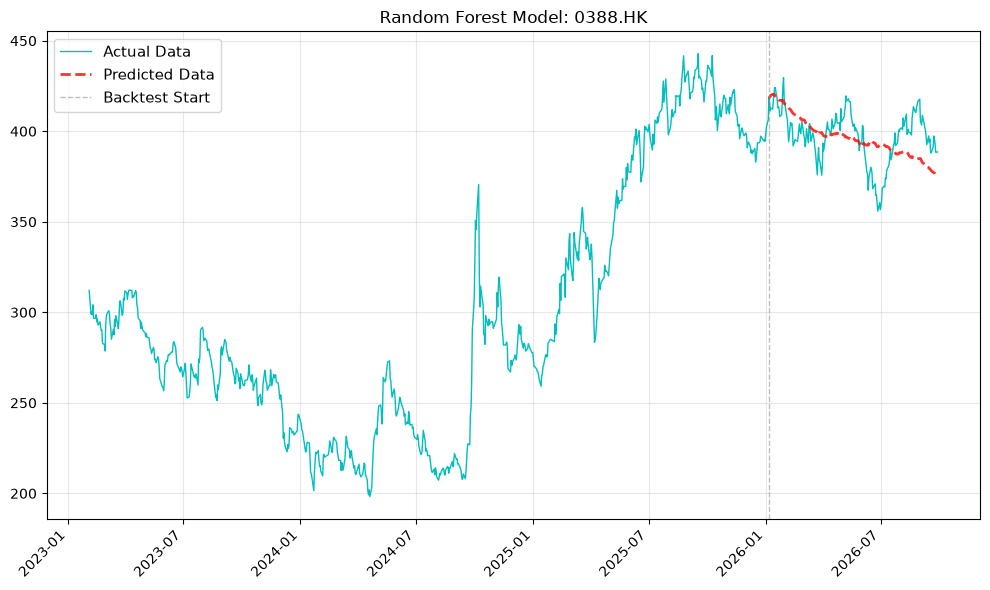

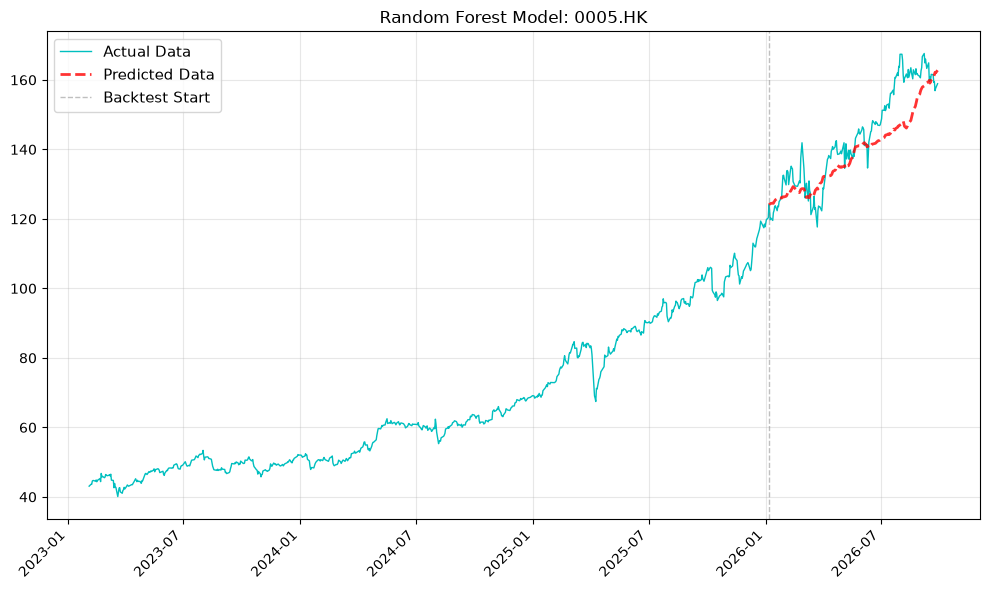

In [31]:
for i in range(len(ticker)):
    plt.figure(figsize=(10,6))
    plt.plot(data[i].Date, data[i].Close, 'c-', label='Actual Data', linewidth=1)
    plt.plot(data[i].Date[-len(close_list[i][0]):], close_list[i][1], 'r--', label="Predicted Data", linewidth=2, alpha=0.8)
    plt.axvline(data[i].Date.iloc[-len(close_list[i][0])], color='gray',linestyle='--', label="Backtest Start", linewidth=1, alpha=0.5)
    plt.grid(alpha=0.3)
    plt.legend(fontsize=11)
    plt.xticks(rotation=45, ha='right')
    plt.title(f"Random Forest Model: {data[i].index.name}")
    plt.tight_layout()
    plt.show()